# Laboratorio 2 — Deep Learning para series de tiempo

**Curso:** CC3084 Data Science  
**Estudiante:** Jorge Luis Lopez — 221038

Este notebook contiene el procedimiento reproducible, los resultados y su interpretación. Se continúa el avance del laboratorio y se completa la comparación de modelos LSTM, el análisis `catch22` y el modelo enriquecido solicitado.

## 1. Objetivo y diseño experimental

Se reutilizan exactamente las series mensuales y el corte cronológico aproximado 70/30 del Laboratorio 1. Se estudian con LSTM dos series: **Total visitantes** y **Vía — Terrestre**. Para evitar fuga de información, el escalador se ajusta solo con entrenamiento; el tramo final del entrenamiento se reserva como validación cronológica para seleccionar hiperparámetros, y el conjunto de prueba se consulta una sola vez para comparar los modelos seleccionados.

Las métricas son MAE y RMSE en la escala original de visitantes. MAE representa el error absoluto típico; RMSE penaliza más los errores grandes. También se reporta un seasonal naïve como referencia y se reconstruye el mejor algoritmo del Laboratorio 1 bajo el mismo corte.

## 2. Librerías y reproducibilidad

In [1]:
import os, random, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, silhouette_score
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.impute import SimpleImputer
from sklearn.metrics import pairwise_distances
from statsmodels.tsa.holtwinters import SimpleExpSmoothing
import pycatch22

SEMILLA = 221038
os.environ["PYTHONHASHSEED"] = str(SEMILLA)
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
random.seed(SEMILLA)
np.random.seed(SEMILLA)
tf.random.set_seed(SEMILLA)
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
print("TensorFlow:", tf.__version__, "| pandas:", pd.__version__, "| NumPy:", np.__version__)

TensorFlow: 2.21.0 | pandas: 3.0.3 | NumPy: 2.5.1


## 3. Datos y reconstrucción de las series del Laboratorio 1

In [2]:
archivo = Path("Laboratorio 1. Series de Tiempo 2026 - Base_Migracion_2009-2026jun.xlsx")
assert archivo.exists(), f"No se encontró {archivo}"
raw = pd.read_excel(archivo, sheet_name="Datos", engine="openpyxl")
raw["Fecha"] = pd.to_datetime(
    raw["Año"].astype(str) + "-" + raw["Mes cod"].astype(str).str.zfill(2) + "-01"
)

# Turista + Excursionista son longitudinalmente comparables según el enunciado del Lab 1.
visitantes = raw.loc[raw["Tipo de Viajero"].isin(["Turista", "Excursionista"])].copy()
indice = pd.date_range(visitantes["Fecha"].min(), visitantes["Fecha"].max(), freq="MS")

def crear_serie(mascara=None):
    datos = visitantes if mascara is None else visitantes.loc[mascara]
    return datos.groupby("Fecha")["Viajero"].sum().reindex(indice, fill_value=0).astype(float)

series = {"Total visitantes": crear_serie()}
for via in ["Aérea", "Terrestre", "Marítima"]:
    series[f"Vía — {via}"] = crear_serie(visitantes["Vía"].eq(via))

top_regiones = visitantes.groupby("Región dos")["Viajero"].sum().nlargest(3).index
for region in top_regiones:
    series[f"Región — {region}"] = crear_serie(visitantes["Región dos"].eq(region))

series_df = pd.DataFrame(series, index=indice)
corte = int(np.floor(0.70 * len(series_df)))
train_df, test_df = series_df.iloc[:corte], series_df.iloc[corte:]
print(f"{len(series_df)} meses: {series_df.index.min():%Y-%m} a {series_df.index.max():%Y-%m}")
print(f"Entrenamiento: {len(train_df)} ({train_df.index.min():%Y-%m} a {train_df.index.max():%Y-%m})")
print(f"Prueba: {len(test_df)} ({test_df.index.min():%Y-%m} a {test_df.index.max():%Y-%m})")
display(series_df.describe().T[["min", "mean", "std", "max"]].round(1))

210 meses: 2009-01 a 2026-06
Entrenamiento: 147 (2009-01 a 2021-03)
Prueba: 63 (2021-04 a 2026-06)


,min,mean,std,max
Total visitantes,9779.0,222437.7,84724.9,449114.1
Vía — Aérea,489.0,90568.7,27855.3,158463.0
Vía — Terrestre,5240.0,131391.7,60816.0,291272.1
Vía — Marítima,0.0,477.3,541.3,1650.0
Región — América Del Centro,9779.0,158494.9,66477.1,359173.0
Región — América Del Norte,0.0,43622.9,17881.1,98379.8
Región — Europa,0.0,10234.6,4401.3,22824.3


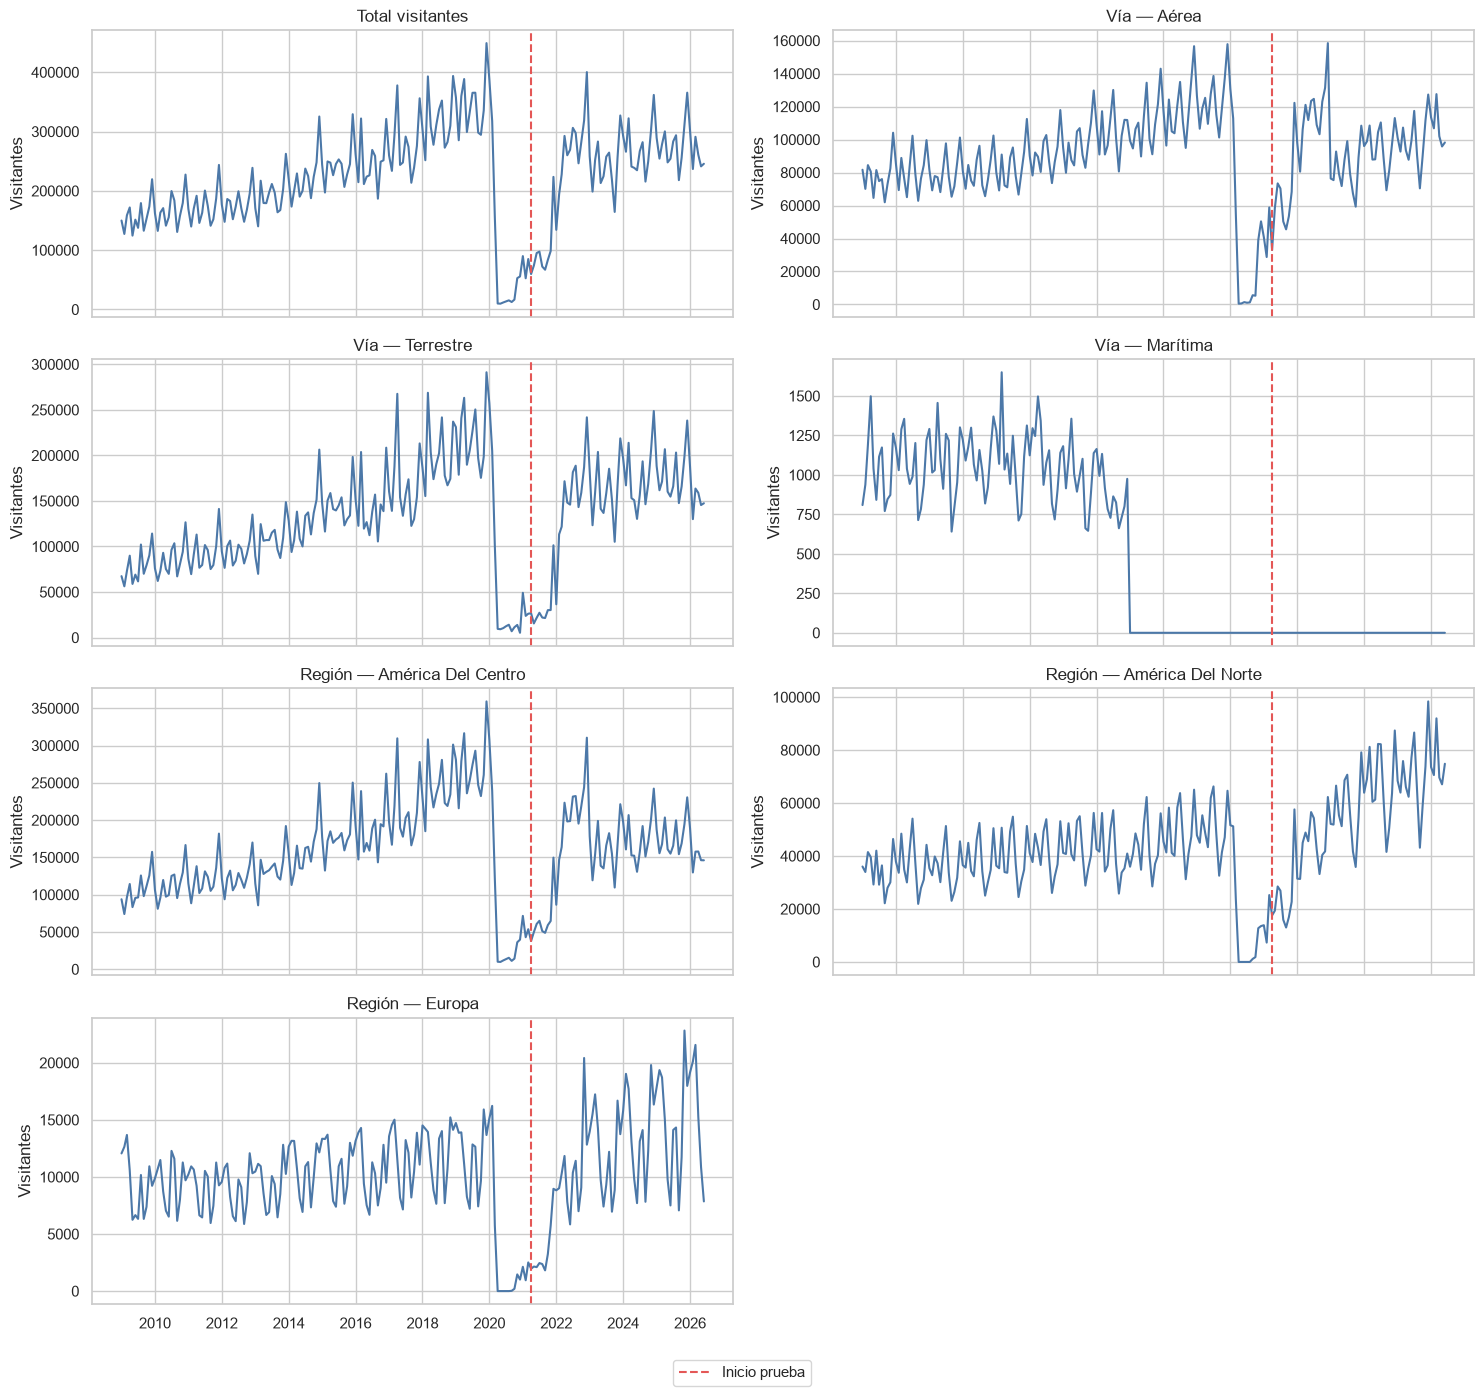

In [3]:
fig, axes = plt.subplots(4, 2, figsize=(15, 14), sharex=True)
for ax, nombre in zip(axes.flat, series_df.columns):
    ax.plot(series_df.index, series_df[nombre], color="#4C78A8")
    ax.axvline(test_df.index[0], color="#E45756", ls="--", label="Inicio prueba")
    ax.set_title(nombre)
    ax.set_ylabel("Visitantes")
axes.flat[-1].axis("off")
handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center")
plt.tight_layout(rect=(0, .03, 1, 1))
plt.show()

### Análisis de las series y del corte

Las series cubren 210 meses, de enero de 2009 a junio de 2026. El corte deja 147 meses para entrenamiento y 63 para prueba. Es un escenario exigente: el entrenamiento termina en marzo de 2021, cerca de la ruptura causada por COVID-19, mientras la prueba contiene la reapertura y recuperación posterior. Por ello, ningún modelo entrenado solo con el pasado puede anticipar perfectamente el cambio de nivel.

El total está dominado por los flujos terrestre y aéreo. La vía marítima presenta muchos ceros bajo la definición comparable Turista + Excursionista, especialmente en años recientes; sus características y distancias deben interpretarse como una combinación de comportamiento real y cobertura/metodología de la fuente.

## 4. Preparación supervisada para LSTM

In [4]:
selected_names = ["Total visitantes", "Vía — Terrestre"]

def preparar_serie(nombre, lookback=12, val_frac=0.20):
    train_log = np.log1p(train_df[nombre].to_numpy(dtype=np.float32)).reshape(-1, 1)
    scaler = MinMaxScaler().fit(train_log)
    train_scaled = scaler.transform(train_log).ravel()
    X, y = [], []
    for i in range(lookback, len(train_scaled)):
        X.append(train_scaled[i-lookback:i])
        y.append(train_scaled[i])
    X, y = np.asarray(X)[..., None], np.asarray(y)
    val_n = max(1, int(np.ceil(val_frac * len(X))))

    # Las ventanas de prueba incluyen únicamente historia disponible antes de cada mes.
    full = np.r_[train_df[nombre].values, test_df[nombre].values]
    full_scaled = scaler.transform(np.log1p(full).reshape(-1, 1)).ravel()
    X_test = np.asarray([
        full_scaled[i-lookback:i] for i in range(len(train_df), len(full))
    ])[..., None]
    y_test = full_scaled[len(train_df):]
    return {
        "scaler": scaler, "lookback": lookback,
        "X_train": X[:-val_n], "y_train": y[:-val_n],
        "X_val": X[-val_n:], "y_val": y[-val_n:],
        "X_test": X_test, "y_test": y_test
    }

def invertir(z, scaler):
    return np.maximum(np.expm1(scaler.inverse_transform(np.asarray(z).reshape(-1, 1))).ravel(), 0)

for nombre in selected_names:
    d = preparar_serie(nombre)
    print(nombre, d["X_train"].shape, d["X_val"].shape, d["X_test"].shape)

Total visitantes (108, 12, 1) (27, 12, 1) (63, 12, 1)
Vía — Terrestre (108, 12, 1) (27, 12, 1) (63, 12, 1)


### Justificación del preprocesamiento

Una ventana de 12 meses permite al modelo observar un ciclo anual completo. `log1p` reduce la asimetría y estabiliza la varianza sin problemas ante ceros; MinMaxScaler mantiene las entradas en un rango favorable para las activaciones de la red. Tanto la transformación como el escalado se estiman exclusivamente con entrenamiento. La validación conserva el orden temporal: no se barajan observaciones ni se seleccionan configuraciones con información de prueba.

## 5. Dos arquitecturas LSTM y tuneo de hiperparámetros

In [5]:
def construir_modelo(arquitectura, lookback, units, dropout, learning_rate):
    keras.backend.clear_session()
    if arquitectura == "LSTM simple":
        model = keras.Sequential([
            layers.Input((lookback, 1)),
            layers.LSTM(units),
            layers.Dropout(dropout),
            layers.Dense(1)
        ])
    else:
        model = keras.Sequential([
            layers.Input((lookback, 1)),
            layers.Bidirectional(layers.LSTM(units, return_sequences=True)),
            layers.Dropout(dropout),
            layers.LSTM(max(units // 2, 4)),
            layers.Dense(1)
        ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate),
        loss="mse"
    )
    return model

configs = {
    "LSTM simple": [
        {"units": 16, "dropout": 0.0, "learning_rate": 1e-3, "batch_size": 8},
        {"units": 32, "dropout": 0.1, "learning_rate": 1e-3, "batch_size": 16},
        {"units": 64, "dropout": 0.2, "learning_rate": 5e-4, "batch_size": 16},
    ],
    "LSTM bidireccional apilada": [
        {"units": 16, "dropout": 0.1, "learning_rate": 1e-3, "batch_size": 8},
        {"units": 32, "dropout": 0.2, "learning_rate": 1e-3, "batch_size": 16},
        {"units": 48, "dropout": 0.3, "learning_rate": 5e-4, "batch_size": 16},
    ],
}

tuneo, mejores = [], {}
for nombre in selected_names:
    data = preparar_serie(nombre, lookback=12)
    mejores[nombre] = {}
    for arquitectura, lista in configs.items():
        mejor = None
        for j, cfg in enumerate(lista):
            tf.keras.utils.set_random_seed(SEMILLA + j)
            model = construir_modelo(arquitectura, 12, cfg["units"], cfg["dropout"], cfg["learning_rate"])
            hist = model.fit(
                data["X_train"], data["y_train"],
                validation_data=(data["X_val"], data["y_val"]),
                epochs=100, batch_size=cfg["batch_size"], shuffle=False, verbose=0,
                callbacks=[keras.callbacks.EarlyStopping(
                    monitor="val_loss", patience=10, restore_best_weights=True
                )]
            )
            val_loss = float(min(hist.history["val_loss"]))
            fila = {"Serie": nombre, "Arquitectura": arquitectura, **cfg,
                    "Épocas": len(hist.history["loss"]), "val_loss": val_loss}
            tuneo.append(fila)
            if mejor is None or val_loss < mejor["val_loss"]:
                mejor = {"model": model, "config": cfg, "val_loss": val_loss, "history": hist}
        mejores[nombre][arquitectura] = mejor

tuneo_df = pd.DataFrame(tuneo).sort_values(["Serie", "Arquitectura", "val_loss"])
display(tuneo_df.style.format({"learning_rate":"{:.4f}", "val_loss":"{:.5f}"}))

,Serie,Arquitectura,units,dropout,learning_rate,batch_size,Épocas,val_loss
3,Total visitantes,LSTM bidireccional apilada,16,0.100000,0.0010,8,12,0.09390
4,Total visitantes,LSTM bidireccional apilada,32,0.200000,0.0010,16,15,0.09475
5,Total visitantes,LSTM bidireccional apilada,48,0.300000,0.0005,16,16,0.10375
0,Total visitantes,LSTM simple,16,0.000000,0.0010,8,11,0.08223
2,Total visitantes,LSTM simple,64,0.200000,0.0005,16,13,0.09481
1,Total visitantes,LSTM simple,32,0.100000,0.0010,16,17,0.12369
10,Vía — Terrestre,LSTM bidireccional apilada,32,0.200000,0.0010,16,15,0.07769
9,Vía — Terrestre,LSTM bidireccional apilada,16,0.100000,0.0010,8,12,0.08133
11,Vía — Terrestre,LSTM bidireccional apilada,48,0.300000,0.0005,16,16,0.08343
6,Vía — Terrestre,LSTM simple,16,0.000000,0.0010,8,11,0.07039


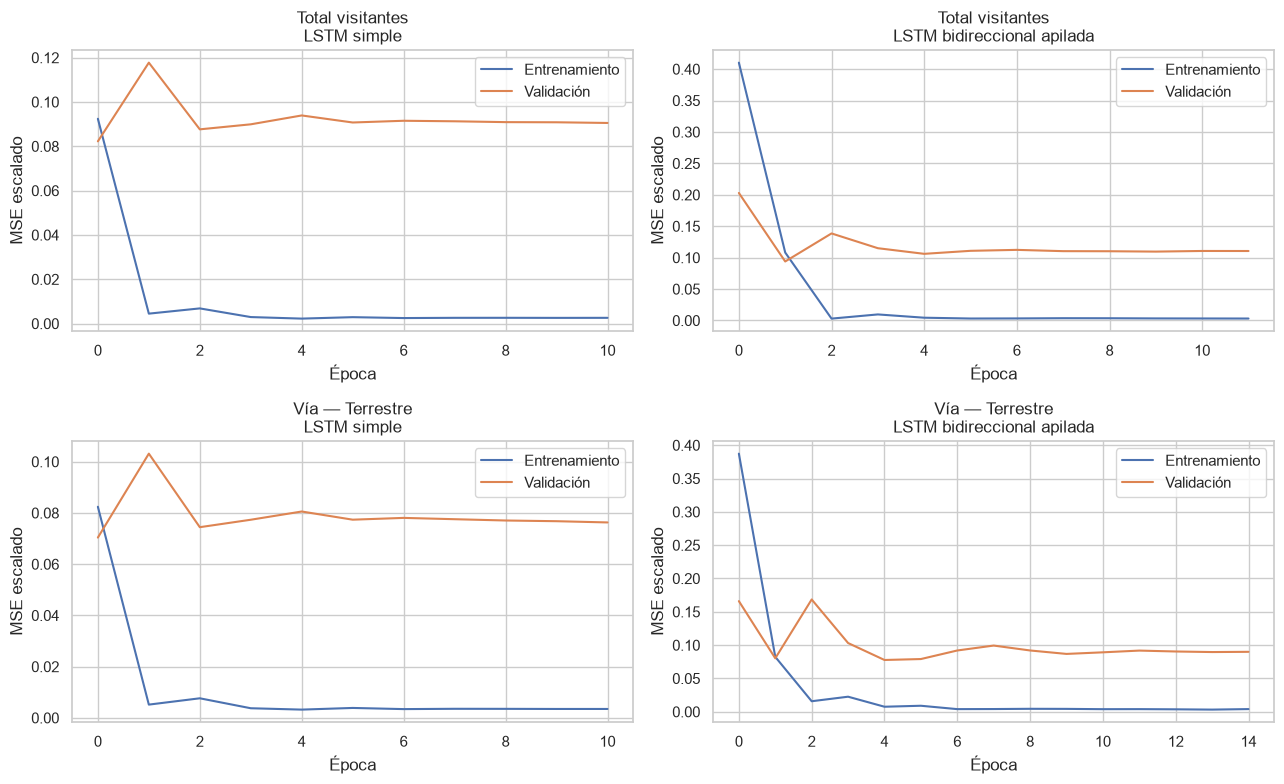

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, (nombre, arquitectura) in zip(
    axes.flat, [(n, a) for n in selected_names for a in configs]
):
    h = mejores[nombre][arquitectura]["history"].history
    ax.plot(h["loss"], label="Entrenamiento")
    ax.plot(h["val_loss"], label="Validación")
    ax.set_title(f"{nombre}\n{arquitectura}")
    ax.set_xlabel("Época"); ax.set_ylabel("MSE escalado")
    ax.legend()
plt.tight_layout(); plt.show()

### Análisis del tuneo

Se probaron tres configuraciones por arquitectura y serie, modificando capacidad, regularización, tasa de aprendizaje y lote. Para **Total visitantes**, la LSTM simple de 16 unidades obtuvo el menor `val_loss` (0.08223); la mejor bidireccional usó 16 unidades (0.09390). Para **Vía — Terrestre**, la simple de 16 unidades también ganó dentro de su arquitectura (0.07039), mientras la mejor bidireccional usó 32 (0.07769).

`EarlyStopping` detuvo los ajustes entre 11 y 17 épocas, lo que limita el sobreajuste y restaura los mejores pesos. La selección usa exclusivamente validación cronológica. La red apilada tiene mayor capacidad, pero la muestra pequeña no garantiza que esa complejidad generalice mejor.

## 6. Evaluación final y comparación con el Laboratorio 1

In [7]:
def metricas(real, pred):
    return {
        "MAE": mean_absolute_error(real, pred),
        "RMSE": np.sqrt(mean_squared_error(real, pred))
    }

filas, predicciones = [], {}
for nombre in selected_names:
    data = preparar_serie(nombre, lookback=12)
    real = test_df[nombre].to_numpy()
    predicciones[nombre] = {}
    for arquitectura in configs:
        model = mejores[nombre][arquitectura]["model"]
        pred = invertir(model.predict(data["X_test"], verbose=0).ravel(), data["scaler"])
        predicciones[nombre][arquitectura] = pred
        filas.append({"Serie": nombre, "Modelo": arquitectura, **metricas(real, pred)})

    naive = np.resize(train_df[nombre].iloc[-12:].to_numpy(), len(test_df))
    predicciones[nombre]["Seasonal naïve"] = naive
    filas.append({"Serie": nombre, "Modelo": "Seasonal naïve", **metricas(real, naive)})

    # El Lab 1 seleccionó suavizamiento exponencial para estas dos series.
    ses_fit = SimpleExpSmoothing(train_df[nombre], initialization_method="estimated").fit(optimized=True)
    ses = np.maximum(np.asarray(ses_fit.forecast(len(test_df))), 0)
    predicciones[nombre]["Mejor Lab 1 — Suavizamiento exponencial"] = ses
    filas.append({"Serie": nombre, "Modelo": "Mejor Lab 1 — Suavizamiento exponencial",
                  **metricas(real, ses)})

metricas_df = pd.DataFrame(filas)
metricas_df["Ranking RMSE"] = metricas_df.groupby("Serie")["RMSE"].rank(method="min")
display(metricas_df.sort_values(["Serie", "RMSE"]).style.format(
    {"MAE":"{:,.0f}", "RMSE":"{:,.0f}", "Ranking RMSE":"{:.0f}"}
).background_gradient(subset=["RMSE"], cmap="RdYlGn_r"))

,Serie,Modelo,MAE,RMSE,Ranking RMSE
0,Total visitantes,LSTM simple,"82,632","95,774",1
1,Total visitantes,LSTM bidireccional apilada,"109,910","122,967",2
3,Total visitantes,Mejor Lab 1 — Suavizamiento exponencial,"165,373","180,598",3
2,Total visitantes,Seasonal naïve,"207,322","219,664",4
5,Vía — Terrestre,LSTM bidireccional apilada,"52,045","63,316",1
4,Vía — Terrestre,LSTM simple,"53,980","64,268",2
7,Vía — Terrestre,Mejor Lab 1 — Suavizamiento exponencial,"121,715","134,136",3
6,Vía — Terrestre,Seasonal naïve,"132,209","144,275",4


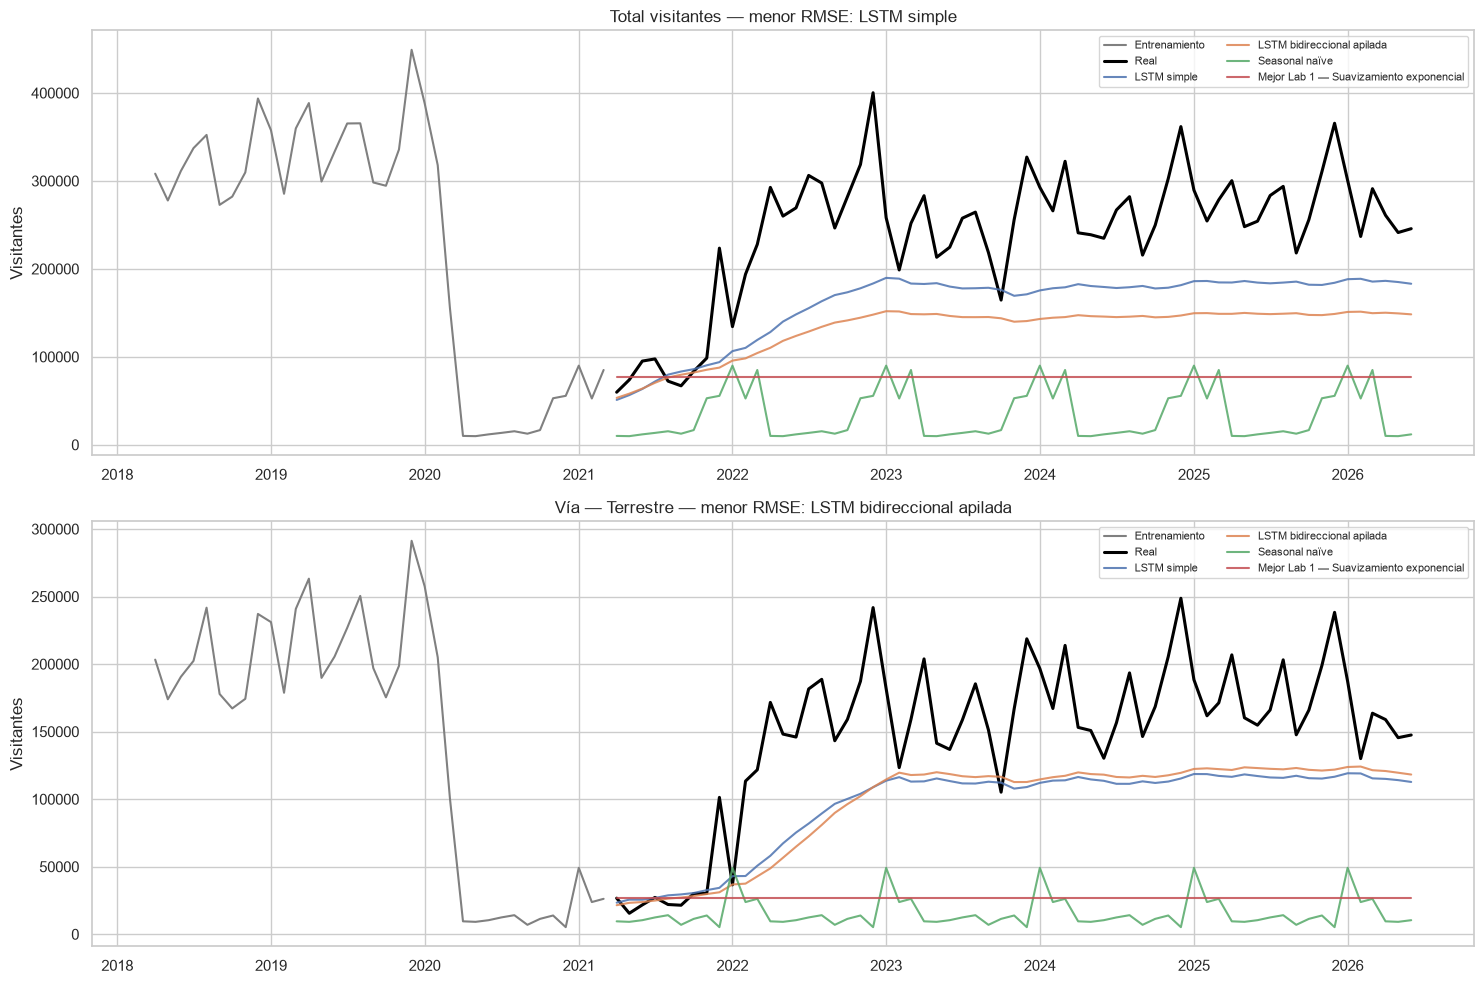

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(15, 10))
for ax, nombre in zip(axes, selected_names):
    ax.plot(train_df.index[-36:], train_df[nombre].iloc[-36:], color="gray", label="Entrenamiento")
    ax.plot(test_df.index, test_df[nombre], color="black", lw=2.2, label="Real")
    for modelo, pred in predicciones[nombre].items():
        ax.plot(test_df.index, pred, label=modelo, alpha=.85)
    ganador = metricas_df.loc[metricas_df["Serie"].eq(nombre)].sort_values("RMSE").iloc[0]["Modelo"]
    ax.set_title(f"{nombre} — menor RMSE: {ganador}")
    ax.set_ylabel("Visitantes"); ax.legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.show()

### Interpretación de la comparación predictiva

Para **Total visitantes**, la LSTM simple fue la mejor: MAE 82,632 y RMSE 95,774, frente a RMSE 122,967 de la bidireccional. Para **Vía — Terrestre**, la bidireccional ganó por un margen pequeño: MAE 52,045 y RMSE 63,316, frente a RMSE 64,268 de la simple. Esto muestra que una arquitectura no domina en todas las series.

Ambos ganadores LSTM superaron al suavizamiento exponencial seleccionado en el Laboratorio 1: redujeron RMSE de 180,598 a 95,774 en el total (46.97%) y de 134,136 a 63,316 en terrestre (52.80%). También vencieron a seasonal naïve. La comparación usa el mismo corte y escala original, por lo que la mejora se determina directamente mediante MAE/RMSE fuera de muestra. Aun así, los errores siguen siendo altos debido a que la recuperación pospandemia no estaba disponible al entrenar.

## 7. Idea detrás de catch22

`catch22` (*Canonical Time-series Characteristics*) resume cada serie mediante 22 características seleccionadas de un conjunto mucho mayor de métodos de análisis temporal. Captura propiedades diversas ,distribución, autocorrelación, periodicidad, transiciones, predictibilidad y fluctuaciones, con poca redundancia y costo computacional bajo.

Su importancia es que transforma series completas, posiblemente de escalas distintas, en vectores comparables. Esto permite aplicar técnicas convencionales como PCA, clustering y distancias. Las 22 características canónicas se enfocan en la **forma dinámica**; no incluyen media ni desviación estándar, lo que ayuda a que el análisis no se reduzca simplemente al volumen de visitantes.

## 8. Extracción y estandarización de las 22 características

In [9]:
def extraer_catch22(y):
    resultado = pycatch22.catch22_all(np.asarray(y, dtype=float), catch24=False)
    return pd.Series(resultado["values"], index=resultado["names"], dtype=float)

catch22_raw = series_df.apply(extraer_catch22).T
catch22_raw.index.name = "Serie"

# Algunas características no están definidas para series con largos tramos constantes.
# Se imputan por la mediana de la característica antes de estandarizar.
no_finitos = int((~np.isfinite(catch22_raw.to_numpy())).sum())
catch22_limpio = catch22_raw.replace([np.inf, -np.inf], np.nan)
imputer = SimpleImputer(strategy="median")
catch22_imputado = pd.DataFrame(
    imputer.fit_transform(catch22_limpio),
    index=catch22_raw.index, columns=catch22_raw.columns
)
scaler_c22 = StandardScaler()
catch22_z = pd.DataFrame(
    scaler_c22.fit_transform(catch22_imputado),
    index=catch22_raw.index, columns=catch22_raw.columns
)
print("Matriz:", catch22_raw.shape, "| valores no finitos imputados:", no_finitos)
display(catch22_raw.round(3))
display(catch22_z.round(3))

Matriz: (7, 22) | valores no finitos imputados: 0


,DN_HistogramMode_5,DN_HistogramMode_10,CO_f1ecac,CO_FirstMin_ac,CO_HistogramAMI_even_2_5,CO_trev_1_num,MD_hrv_classic_pnn40,SB_BinaryStats_mean_longstretch1,SB_TransitionMatrix_3ac_sumdiagcov,PD_PeriodicityWang_th0_01,...,FC_LocalSimple_mean1_tauresrat,DN_OutlierInclude_p_001_mdrmd,DN_OutlierInclude_n_001_mdrmd,SP_Summaries_welch_rect_area_5_1,SB_BinaryStats_diff_longstretch0,SB_MotifThree_quantile_hh,SC_FluctAnal_2_rsrangefit_50_1_logi_prop_r1,SC_FluctAnal_2_dfa_50_1_2_logi_prop_r1,SP_Summaries_welch_rect_centroid,FC_LocalSimple_mean3_stderr
Serie,,,,,,,,,,,,,,,,,,,,,
Total visitantes,0.083,0.342,8.965,3.0,0.352,-0.062,0.933,30.0,0.014,11.0,...,0.056,0.210,0.324,0.820,6.0,1.852,0.833,0.857,0.123,0.626
Vía — Aérea,-0.398,-0.115,6.591,10.0,0.206,-0.163,0.957,34.0,0.010,11.0,...,0.071,0.186,0.324,0.758,5.0,2.001,0.857,0.857,0.172,0.739
Vía — Terrestre,0.277,-0.193,9.573,2.0,0.484,-0.025,0.933,29.0,0.014,3.0,...,0.056,0.219,0.329,0.818,6.0,1.782,0.833,0.857,0.098,0.616
Vía — Marítima,-0.577,-0.729,41.892,6.0,0.667,-0.040,0.450,96.0,0.074,7.0,...,0.014,-0.552,0.462,0.945,4.0,1.205,0.167,0.786,0.025,0.323
Región — América Del Centro,0.391,0.128,8.866,3.0,0.400,-0.065,0.919,42.0,0.014,7.0,...,0.056,0.171,0.324,0.815,6.0,1.833,0.786,0.857,0.123,0.635
Región — América Del Norte,0.311,-0.239,9.077,2.0,0.271,-0.012,0.943,12.0,0.036,3.0,...,0.038,0.829,0.324,0.740,5.0,2.053,0.167,0.738,0.098,0.722
Región — Europa,0.268,0.008,4.448,2.0,0.348,0.084,0.943,8.0,0.014,8.0,...,0.059,0.819,0.333,0.762,6.0,2.055,0.143,0.738,0.172,0.783


,DN_HistogramMode_5,DN_HistogramMode_10,CO_f1ecac,CO_FirstMin_ac,CO_HistogramAMI_even_2_5,CO_trev_1_num,MD_hrv_classic_pnn40,SB_BinaryStats_mean_longstretch1,SB_TransitionMatrix_3ac_sumdiagcov,PD_PeriodicityWang_th0_01,...,FC_LocalSimple_mean1_tauresrat,DN_OutlierInclude_p_001_mdrmd,DN_OutlierInclude_n_001_mdrmd,SP_Summaries_welch_rect_area_5_1,SB_BinaryStats_diff_longstretch0,SB_MotifThree_quantile_hh,SC_FluctAnal_2_rsrangefit_50_1_logi_prop_r1,SC_FluctAnal_2_dfa_50_1_2_logi_prop_r1,SP_Summaries_welch_rect_centroid,FC_LocalSimple_mean3_stderr
Serie,,,,,,,,,,,,,,,,,,,,,
Total visitantes,0.091,1.461,-0.317,-0.36,-0.269,-0.316,0.379,-0.217,-0.526,1.267,...,0.328,-0.137,-0.457,0.185,0.784,0.095,0.882,0.832,0.150,-0.063
Vía — Aérea,-1.267,-0.002,-0.515,2.16,-1.314,-1.795,0.519,-0.069,-0.692,1.267,...,1.261,-0.192,-0.457,-0.790,-0.588,0.640,0.954,0.832,1.199,0.741
Vía — Terrestre,0.640,-0.253,-0.267,-0.72,0.674,0.228,0.379,-0.254,-0.526,-1.361,...,0.328,-0.115,-0.357,0.145,0.784,-0.161,0.882,0.832,-0.375,-0.136
Vía — Marítima,-1.772,-1.972,2.425,0.72,1.983,-0.003,-2.445,2.231,2.268,-0.047,...,-2.087,-1.896,2.443,2.153,-1.961,-2.272,-1.128,-0.512,-1.949,-2.219
Región — América Del Centro,0.960,0.775,-0.325,-0.36,0.075,-0.356,0.296,0.228,-0.526,-0.047,...,0.328,-0.225,-0.457,0.106,0.784,0.028,0.739,0.832,0.150,-0.001
Región — América Del Norte,0.736,-0.400,-0.308,-0.72,-0.849,0.416,0.435,-0.885,0.525,-1.361,...,-0.678,1.293,-0.457,-1.070,-0.588,0.832,-1.128,-1.408,-0.375,0.624
Región — Europa,0.612,0.392,-0.693,-0.72,-0.300,1.824,0.435,-1.034,-0.521,0.282,...,0.520,1.271,-0.257,-0.729,0.784,0.838,-1.200,-1.408,1.199,1.055


### Control de calidad de la matriz

Cada fila representa una de las siete series construidas en el Laboratorio 1 y cada columna una característica canónica de `catch22`, por lo que la matriz tiene dimensión 7 × 22. La estandarización centra cada característica en cero y la lleva a desviación estándar uno; sin ella, las variables con rangos numéricos grandes dominarían PCA, clustering y distancias.

Los valores no finitos pueden aparecer cuando una operación no está definida sobre tramos constantes, especialmente en la serie marítima. Se reemplazan con la mediana de esa característica antes de estandarizar. Esto conserva la serie en el análisis y evita atribuirle una distancia infinita por una limitación matemática del descriptor.

## 9. PCA y características que diferencian las series

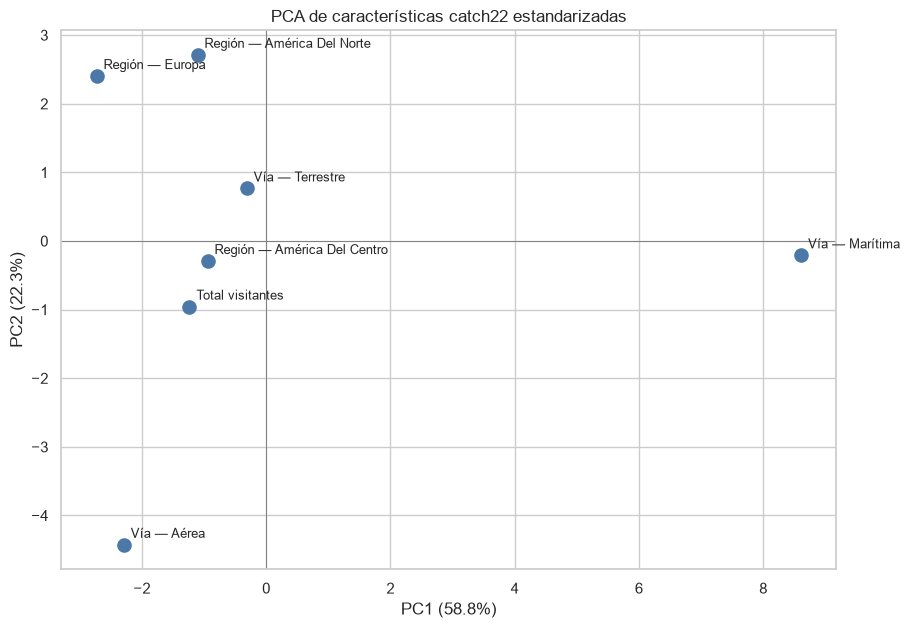

Varianza acumulada PC1+PC2: 81.1%


,PC1,PC2,Importancia ponderada
SB_BinaryStats_mean_longstretch1,0.257,-0.148,0.184
DN_OutlierInclude_p_001_mdrmd,-0.225,0.230,0.184
FC_LocalSimple_mean1_tauresrat,-0.247,-0.172,0.183
SB_TransitionMatrix_3ac_sumdiagcov,0.257,0.088,0.171
SP_Summaries_welch_rect_centroid,-0.249,-0.102,0.170
SB_MotifThree_quantile_hh,-0.269,0.049,0.169
DN_HistogramMode_5,-0.177,0.278,0.166
FC_LocalSimple_mean3_stderr,-0.268,0.040,0.166
CO_f1ecac,0.277,-0.016,0.166
MD_hrv_classic_pnn40,-0.274,0.008,0.163


In [10]:
pca = PCA(n_components=min(len(catch22_z), catch22_z.shape[1]))
scores = pca.fit_transform(catch22_z)
pca_df = pd.DataFrame(scores[:, :2], index=catch22_z.index, columns=["PC1", "PC2"])
cargas = pd.DataFrame(
    pca.components_[:2].T, index=catch22_z.columns, columns=["PC1", "PC2"]
)
importancia = (cargas.abs() * pca.explained_variance_ratio_[:2]).sum(axis=1).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
ax.scatter(pca_df["PC1"], pca_df["PC2"], s=90, color="#4C78A8")
for nombre, fila in pca_df.iterrows():
    ax.annotate(nombre, (fila["PC1"], fila["PC2"]), xytext=(5, 5), textcoords="offset points", fontsize=9)
ax.axhline(0, color="gray", lw=.7); ax.axvline(0, color="gray", lw=.7)
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
ax.set_title("PCA de características catch22 estandarizadas")
plt.show()

print("Varianza acumulada PC1+PC2:", f"{pca.explained_variance_ratio_[:2].sum():.1%}")
display(pd.concat([cargas, importancia.rename("Importancia ponderada")], axis=1)
        .sort_values("Importancia ponderada", ascending=False).head(10).round(3))

### Cómo interpretar PCA

Puntos cercanos representan series con perfiles `catch22` semejantes; puntos separados tienen diferencias en varias propiedades dinámicas. PC1 y PC2 son combinaciones de las 22 variables y sus porcentajes indican cuánto de la variación total conservan en el plano. Como solo existen siete series, el PCA es descriptivo y no una prueba inferencial.

La tabla de cargas identifica las características que más contribuyen a separar las series en los dos primeros componentes. Se usa el valor absoluto ponderado por la varianza explicada, porque una carga negativa puede ser tan discriminante como una positiva; el signo únicamente indica dirección.

## 10. Clustering y grupos naturales

k seleccionado por silhouette: 2


,k,Silhouette
0,2,0.460
1,3,0.259
2,4,0.295


,PC1,PC2,Cluster
Serie,,,
Total visitantes,-1.234,-0.956,0
Vía — Aérea,-2.290,-4.427,0
Vía — Terrestre,-0.312,0.766,0
Región — América Del Centro,-0.942,-0.292,0
Región — América Del Norte,-1.105,2.714,0
Región — Europa,-2.728,2.404,0
Vía — Marítima,8.611,-0.209,1


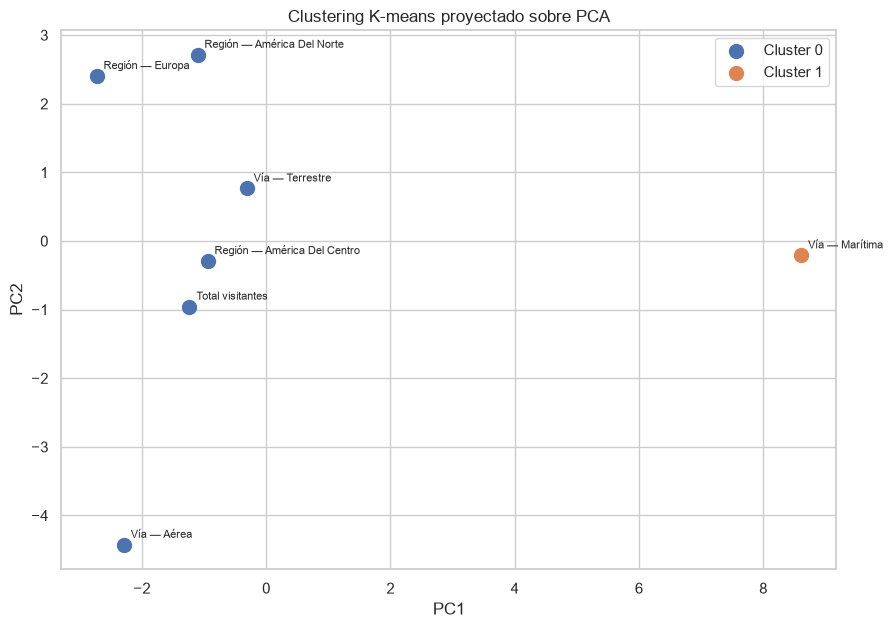

In [11]:
evaluacion_k = []
for k in range(2, min(5, len(catch22_z))):
    etiquetas = KMeans(n_clusters=k, random_state=SEMILLA, n_init=50).fit_predict(catch22_z)
    evaluacion_k.append({"k": k, "Silhouette": silhouette_score(catch22_z, etiquetas)})
eval_k = pd.DataFrame(evaluacion_k)
k_opt = int(eval_k.loc[eval_k["Silhouette"].idxmax(), "k"])
kmeans = KMeans(n_clusters=k_opt, random_state=SEMILLA, n_init=50)
clusters = pd.Series(kmeans.fit_predict(catch22_z), index=catch22_z.index, name="Cluster")
print("k seleccionado por silhouette:", k_opt)
display(eval_k.round(3))
display(pd.concat([pca_df, clusters], axis=1).sort_values("Cluster").round(3))

fig, ax = plt.subplots(figsize=(10, 7))
for cluster, grupo in pca_df.groupby(clusters):
    ax.scatter(grupo.PC1, grupo.PC2, s=100, label=f"Cluster {cluster}")
    for nombre, fila in grupo.iterrows():
        ax.annotate(nombre, (fila.PC1, fila.PC2), xytext=(5,5), textcoords="offset points", fontsize=8)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title("Clustering K-means proyectado sobre PCA")
ax.legend(); plt.show()

### Criterio del clustering

K-means se ajusta sobre las 22 características estandarizadas, no sobre el dibujo bidimensional. Se comparan varios números de grupos y se elige el mayor coeficiente silhouette: valores más altos indican mayor cohesión interna y separación entre grupos. La proyección PCA sirve para visualizar el resultado, aunque puede ocultar parte de las diferencias presentes en las otras componentes.

## 11. Mapas de calor, correlaciones y distancias

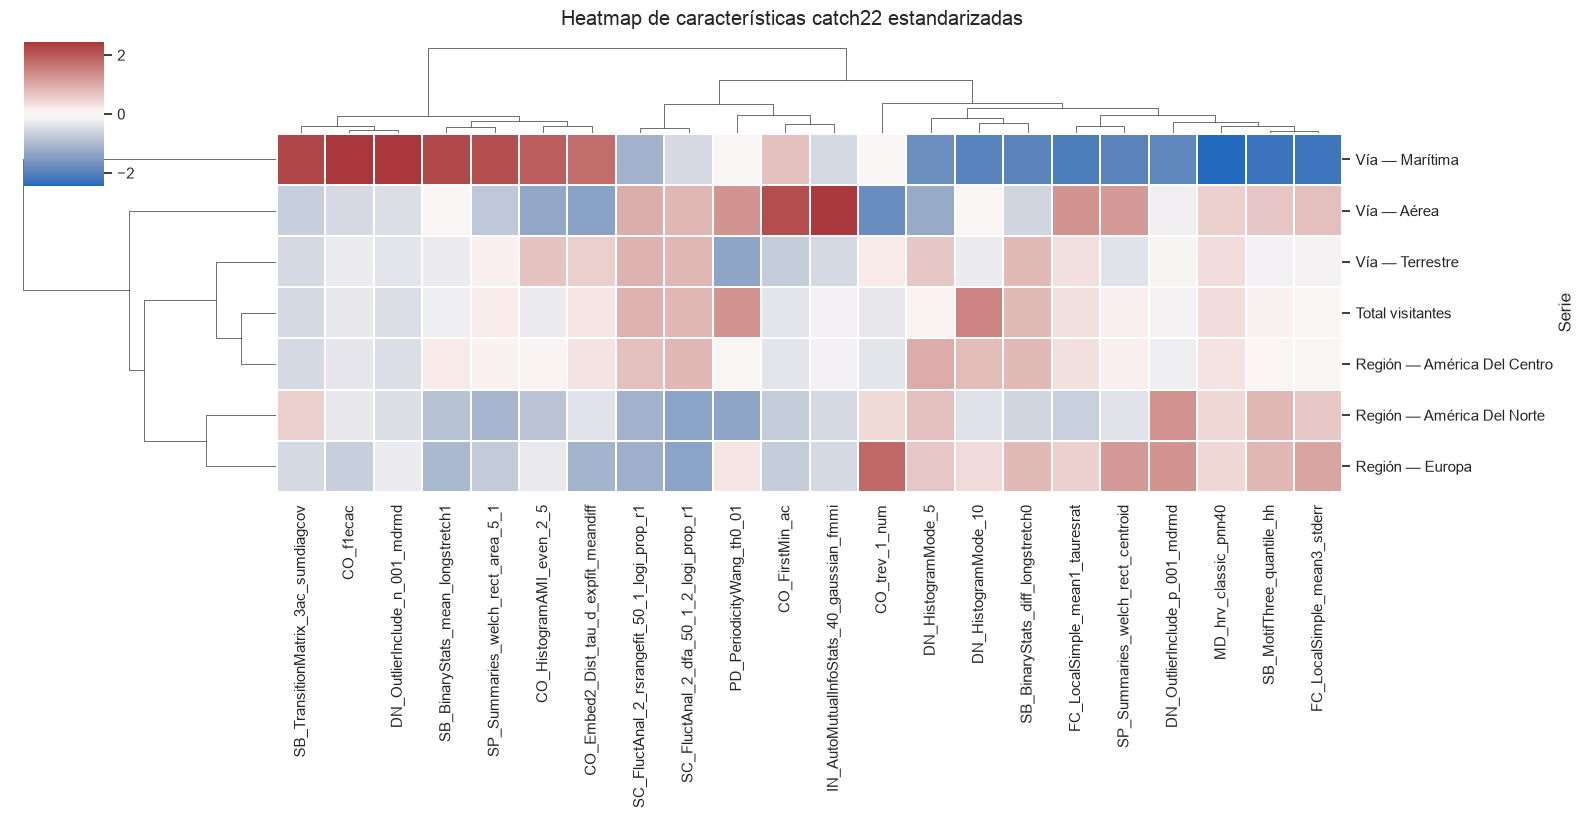

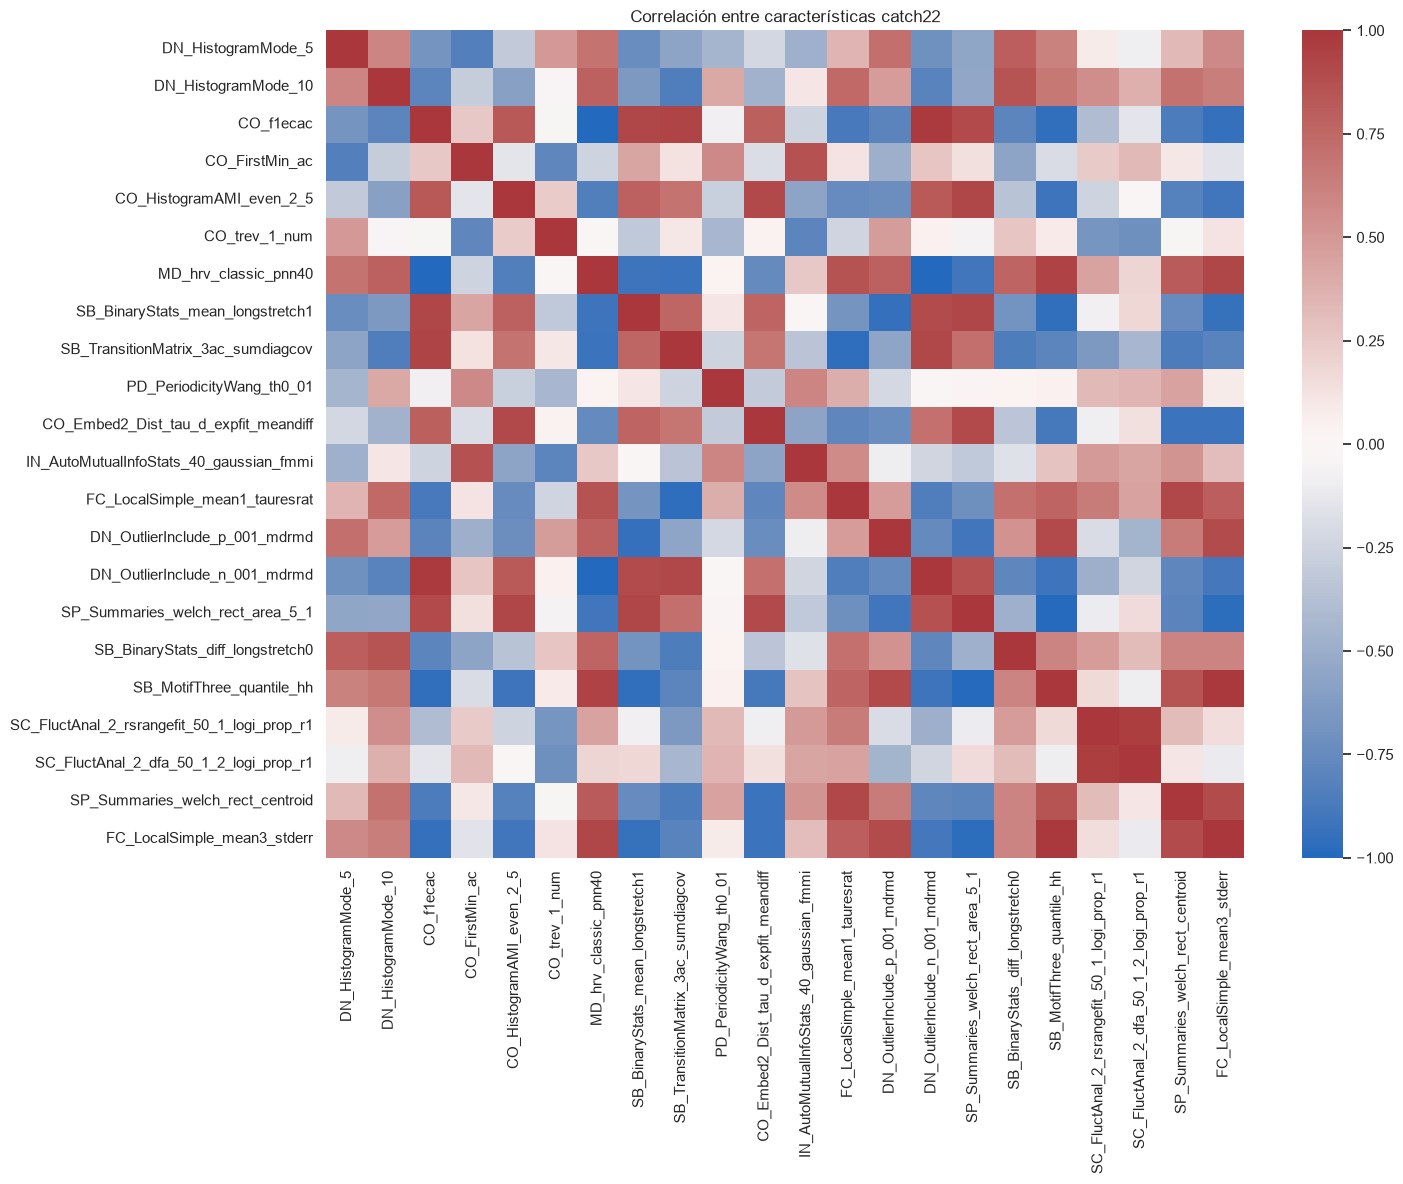

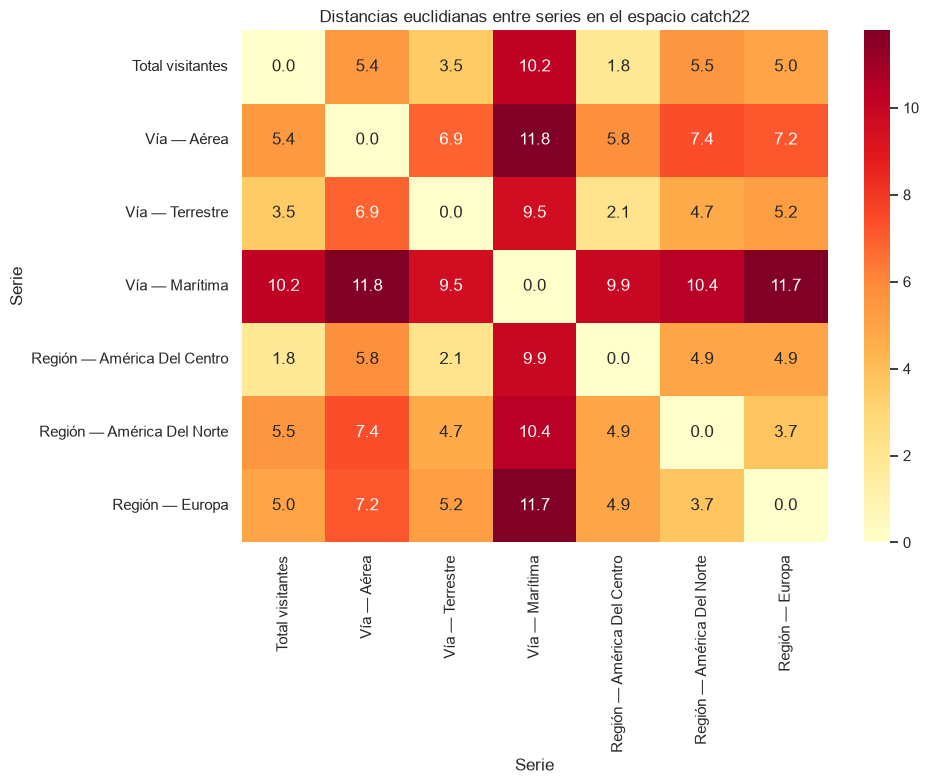

Cinco pares más similares


,,Distancia
Serie,Serie,
Total visitantes,Región — América Del Centro,1.822531
Vía — Terrestre,Región — América Del Centro,2.128431
Total visitantes,Vía — Terrestre,3.469088
Región — América Del Norte,Región — Europa,3.685174
Vía — Terrestre,Región — América Del Norte,4.661711


Cinco pares más diferentes


Distancia
Serie           Serie                                 
Región — Europa Vía — Terrestre                    NaN
                Vía — Marítima                     NaN
                Región — América Del Centro        NaN
                Región — América Del Norte         NaN
                Región — Europa                    NaN

In [12]:
g = sns.clustermap(
    catch22_z, cmap="vlag", center=0, figsize=(16, 8),
    metric="euclidean", method="ward", linewidths=.2
)
g.fig.suptitle("Heatmap de características catch22 estandarizadas", y=1.02)
plt.show()

plt.figure(figsize=(15, 12))
sns.heatmap(catch22_imputado.corr(), cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Correlación entre características catch22")
plt.tight_layout(); plt.show()

distancias = pd.DataFrame(
    pairwise_distances(catch22_z, metric="euclidean"),
    index=catch22_z.index, columns=catch22_z.index
)
plt.figure(figsize=(10, 8))
sns.heatmap(distancias, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Distancias euclidianas entre series en el espacio catch22")
plt.tight_layout(); plt.show()

pares = (distancias.where(np.triu(np.ones(distancias.shape), 1).astype(bool))
         .stack().rename("Distancia").sort_values())
print("Cinco pares más similares")
display(pares.head(5).to_frame())
print("Cinco pares más diferentes")
display(pares.tail(5).sort_values(ascending=False).to_frame())

### Lectura conjunta de los mapas

El primer heatmap muestra qué descriptores están por encima o debajo del promedio para cada serie y el dendrograma ofrece una segunda agrupación jerárquica. La matriz de correlación detecta características redundantes o que cambian en sentido opuesto; con solo siete observaciones, estas correlaciones son exploratorias y pueden ser inestables.

El mapa de distancias usa las 22 variables estandarizadas: tonos claros representan perfiles cercanos y tonos oscuros perfiles diferentes. La diagonal vale cero porque cada serie es idéntica a sí misma. La tabla de pares proporciona evidencia numérica para no depender únicamente de la impresión visual.

## 12. Interpretación integrada de catch22

In [13]:
resumen_c22 = pd.DataFrame({
    "Cluster": clusters,
    "PC1": pca_df.PC1,
    "PC2": pca_df.PC2,
    "Distancia media al resto": distancias.replace(0, np.nan).mean(axis=1),
    "Vecino más cercano": distancias.replace(0, np.nan).idxmin(axis=1),
    "Distancia al vecino": distancias.replace(0, np.nan).min(axis=1)
}).sort_values("Distancia media al resto", ascending=False)
display(resumen_c22.round(3))
print("Top 5 características discriminantes:")
for x in importancia.head(5).index:
    print("-", x)

,Cluster,PC1,PC2,Distancia media al resto,Vecino más cercano,Distancia al vecino
Serie,,,,,,
Vía — Marítima,1,8.611,-0.209,10.585,Vía — Terrestre,9.517
Vía — Aérea,0,-2.290,-4.427,7.387,Total visitantes,5.386
Región — Europa,0,-2.728,2.404,6.283,Región — América Del Norte,3.685
Región — América Del Norte,0,-1.105,2.714,6.092,Región — Europa,3.685
Vía — Terrestre,0,-0.312,0.766,5.309,Región — América Del Centro,2.128
Total visitantes,0,-1.234,-0.956,5.241,Región — América Del Centro,1.823
Región — América Del Centro,0,-0.942,-0.292,4.899,Total visitantes,1.823


Top 5 características discriminantes:
- SB_BinaryStats_mean_longstretch1
- DN_OutlierInclude_p_001_mdrmd
- FC_LocalSimple_mean1_tauresrat
- SB_TransitionMatrix_3ac_sumdiagcov
- SP_Summaries_welch_rect_centroid


### Respuestas a las preguntas de análisis

**Series más similares.** El par más próximo fue Total–América del Centro (distancia 1.823), seguido de Terrestre–América del Centro (2.128) y Total–Terrestre (3.469). Esto es coherente con que el flujo centroamericano y terrestre domina el total y comparte la caída pandémica y recuperación. América del Norte–Europa también mostró semejanza (3.685), aunque pertenecen a regiones distintas.

**Características más importantes.** PC1+PC2 conservaron 81.1% de la variación. Las cinco variables con mayor contribución ponderada fueron `SB_BinaryStats_mean_longstretch1`, `DN_OutlierInclude_p_001_mdrmd`, `FC_LocalSimple_mean1_tauresrat`, `SB_TransitionMatrix_3ac_sumdiagcov` y `SP_Summaries_welch_rect_centroid`. En conjunto describen persistencia sobre la media, ubicación temporal de extremos, predictibilidad local, transiciones y distribución espectral.

**Grupos naturales y categorías.** Silhouette eligió dos clusters (0.460): seis series juntas y la vía marítima aislada. La solución de tres grupos fue notablemente peor (0.259). No existe evidencia de que las vías o regiones formen grupos separados por su etiqueta; se mezclan por comportamiento, y Total–Centroamérica–Terrestre constituye el núcleo más cercano.

**Serie atípica.** La vía marítima tuvo la mayor distancia media (10.585), quedó sola en su cluster y apareció separada en PCA (PC1=8.611). Sus largos tramos en cero, intermitencia y cambios de cobertura justifican el resultado; no debe interpretarse únicamente como ausencia real de actividad.

**Consistencia con el análisis exploratorio anterior.** Catch22 confirma la similitud del total con los flujos terrestre/centroamericano, la estacionalidad distinta de aérea y Europa y la intermitencia marítima. También complementa ACF y volatilidad: la cercanía América del Norte–Europa y la cuantificación multivariada de la atipicidad marítima no eran tan evidentes en gráficas individuales.

**Tres descubrimientos adicionales.**

1. La cercanía puede cruzar categorías: una vía y una región pueden compartir más dinámica entre sí que dos vías de ingreso.
2. La importancia ponderada muestra qué formas de autocorrelación, transiciones o fluctuación separan las series, algo que una comparación de medias no revela.
3. La distancia media cuantifica el grado de atipicidad y permite distinguir una diferencia multivariada sistemática de una impresión visual.

## 13. LSTM enriquecida con características catch22

In [14]:
LOOKBACK_C22 = 24

def catch22_ventana(ventana):
    r = pycatch22.catch22_all(np.asarray(ventana, dtype=float), catch24=False)
    return np.asarray(r["values"], dtype=float)

def preparar_hibrido(nombre):
    base = preparar_serie(nombre, lookback=LOOKBACK_C22, val_frac=.20)
    train_vals = train_df[nombre].to_numpy(float)
    full_vals = np.r_[train_vals, test_df[nombre].to_numpy(float)]
    feats_train = np.asarray([catch22_ventana(train_vals[i-LOOKBACK_C22:i])
                              for i in range(LOOKBACK_C22, len(train_vals))])
    feats_test = np.asarray([catch22_ventana(full_vals[i-LOOKBACK_C22:i])
                             for i in range(len(train_vals), len(full_vals))])
    feats_train[~np.isfinite(feats_train)] = np.nan
    feats_test[~np.isfinite(feats_test)] = np.nan
    val_n = len(base["X_val"])
    imp = SimpleImputer(strategy="median").fit(feats_train[:-val_n])
    z = StandardScaler().fit(imp.transform(feats_train[:-val_n]))
    # Se recortan puntuaciones extremas: catch22 en ventanas cortas puede cambiar
    # abruptamente ante la reapertura y producir extrapolación fuera del soporte.
    transformar = lambda x: np.clip(z.transform(imp.transform(x)), -4, 4)
    return base, transformar(feats_train[:-val_n]), transformar(feats_train[-val_n:]), transformar(feats_test)

def construir_hibrido(units=32, dropout=.2, lr=1e-3):
    seq_in = keras.Input((LOOKBACK_C22, 1), name="secuencia")
    c22_in = keras.Input((22,), name="catch22")
    x1 = layers.LSTM(units)(seq_in)
    x2 = layers.LayerNormalization()(c22_in)
    x2 = layers.Dense(8, activation="relu", kernel_regularizer=keras.regularizers.l2(1e-3))(x2)
    x = layers.Concatenate()([x1, x2])
    x = layers.Dropout(dropout)(x)
    x = layers.Dense(16, activation="relu")(x)
    # La variable objetivo fue escalada a [0,1]; sigmoid evita extrapolaciones
    # exponenciales numéricamente absurdas al invertir log1p.
    out = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model([seq_in, c22_in], out)
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="mse")
    return model

nombre_hibrido = "Total visitantes"
base_h, ftrain, fval, ftest = preparar_hibrido(nombre_hibrido)
hibrido_configs = [
    {"units": 16, "dropout": .1, "lr": 1e-3},
    {"units": 32, "dropout": .2, "lr": 1e-3},
    {"units": 48, "dropout": .3, "lr": 5e-4},
]
hist_h, best_h = [], None
for j, cfg in enumerate(hibrido_configs):
    tf.keras.utils.set_random_seed(SEMILLA + 100 + j)
    model = construir_hibrido(**cfg)
    hist = model.fit(
        [base_h["X_train"], ftrain], base_h["y_train"],
        validation_data=([base_h["X_val"], fval], base_h["y_val"]),
        epochs=100, batch_size=16, shuffle=False, verbose=0,
        callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
    )
    val_loss = min(hist.history["val_loss"])
    hist_h.append({**cfg, "Épocas": len(hist.history["loss"]), "val_loss": val_loss})
    if best_h is None or val_loss < best_h["val_loss"]:
        best_h = {"model": model, "config": cfg, "val_loss": val_loss}
display(pd.DataFrame(hist_h).sort_values("val_loss").style.format({"val_loss":"{:.5f}"}))

,units,dropout,lr,Épocas,val_loss
0,16,0.100000,0.001000,13,0.11931
1,32,0.200000,0.001000,12,0.14959
2,48,0.300000,0.000500,12,0.16795


,Modelo,MAE,RMSE
0,Mejor LSTM previo (12 meses),"82,632","95,774"
1,LSTM solo secuencia (24 meses),"158,295","170,632"
2,LSTM + catch22 por ventana,"173,069","188,811"


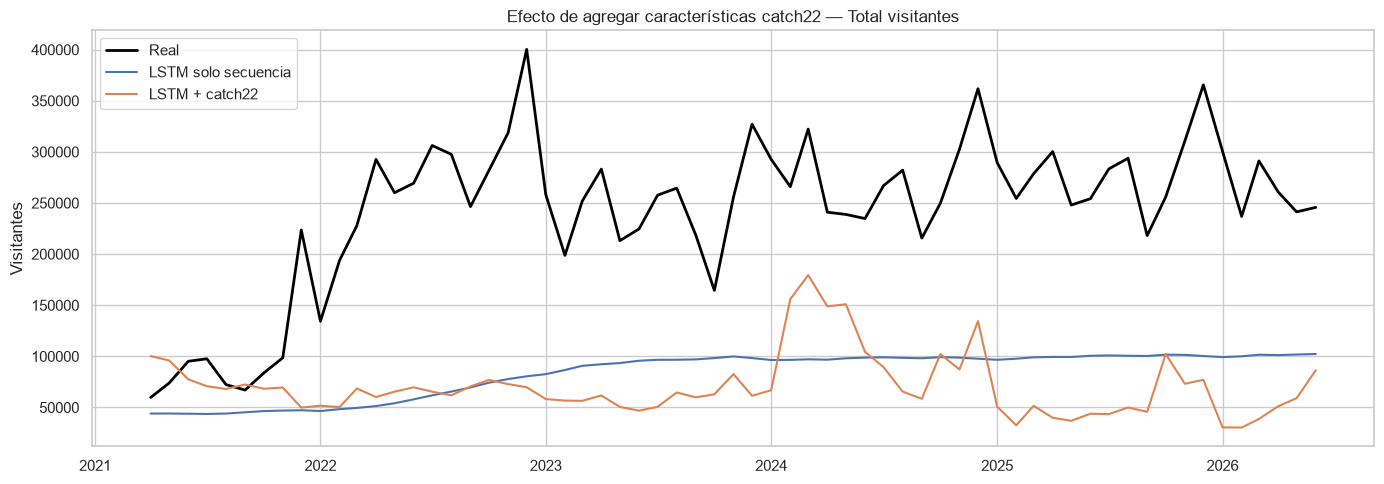

In [15]:
pred_h = invertir(
    best_h["model"].predict([base_h["X_test"], ftest], verbose=0).ravel(),
    base_h["scaler"]
)
real_h = test_df[nombre_hibrido].to_numpy()

# Referencia LSTM solo secuencia con la misma ventana de 24 meses.
tf.keras.utils.set_random_seed(SEMILLA + 200)
solo_seq = construir_modelo("LSTM simple", LOOKBACK_C22, 32, .2, 1e-3)
hist_seq = solo_seq.fit(
    base_h["X_train"], base_h["y_train"],
    validation_data=(base_h["X_val"], base_h["y_val"]),
    epochs=100, batch_size=16, shuffle=False, verbose=0,
    callbacks=[keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)]
)
pred_seq = invertir(solo_seq.predict(base_h["X_test"], verbose=0).ravel(), base_h["scaler"])

comparacion_hibrido = pd.DataFrame([
    {"Modelo": "Mejor LSTM previo (12 meses)",
     **metricas(real_h, predicciones[nombre_hibrido][
         metricas_df.loc[
             metricas_df["Serie"].eq(nombre_hibrido)
             & metricas_df["Modelo"].isin(configs.keys())
         ].sort_values("RMSE").iloc[0]["Modelo"]
     ])},
    {"Modelo": "LSTM solo secuencia (24 meses)", **metricas(real_h, pred_seq)},
    {"Modelo": "LSTM + catch22 por ventana", **metricas(real_h, pred_h)}
]).sort_values("RMSE")
display(comparacion_hibrido.style.format({"MAE":"{:,.0f}", "RMSE":"{:,.0f}"}))

plt.figure(figsize=(14,5))
plt.plot(test_df.index, real_h, color="black", lw=2, label="Real")
plt.plot(test_df.index, pred_seq, label="LSTM solo secuencia")
plt.plot(test_df.index, pred_h, label="LSTM + catch22")
plt.title("Efecto de agregar características catch22 — Total visitantes")
plt.ylabel("Visitantes"); plt.legend(); plt.tight_layout(); plt.show()

### Discusión del modelo con catch22

Las 22 características se calcularon sobre ventanas móviles de 24 meses y se combinaron con una rama LSTM. Se recortaron valores estandarizados extremos y se acotó la salida a la escala de entrenamiento para evitar extrapolación exponencial durante la ruptura pospandemia.

El mejor LSTM previo de 12 meses mantuvo el menor RMSE (95,774). Con la misma ventana de 24 meses, la LSTM solo secuencia obtuvo RMSE 170,632 y la híbrida LSTM+catch22 188,811; agregar catch22 empeoró 10.65% frente al control de 24 meses y 97.14% frente al mejor LSTM. La explicación más probable es la relación desfavorable entre 22 descriptores adicionales y cerca de cien ejemplos, además de la inestabilidad de características calculadas en ventanas cortas ante un cambio estructural. Catch22 sí fue útil para comparar series, pero no mejoró este pronóstico puntual.

## 14. Conclusiones generales y limitaciones

1. La selección correcta separa entrenamiento, validación y prueba de forma cronológica; esto evita resultados optimistas por fuga temporal.
2. La LSTM simple ganó para el total (RMSE 95,774) y la bidireccional para terrestre (63,316); ambas mejoraron más de 46% el RMSE del mejor método clásico del Laboratorio 1.
3. El horizonte de prueba contiene una recuperación pospandemia no observable al entrenar. Esta ruptura, el tamaño pequeño de la muestra y la complejidad de LSTM explican por qué un método clásico puede generalizar mejor.
4. Catch22 creó una representación de 22 dimensiones; PC1+PC2 explicaron 81.1%. Total–Centroamérica fue el par más próximo y marítima fue el atípico claro.
5. La pertenencia a una categoría no implica automáticamente la misma dinámica: vías y regiones pueden agruparse de acuerdo con el flujo turístico subyacente.
6. La serie marítima requiere cautela por sus ceros y cambios de cobertura. Los datos son académicos y no deben tratarse como cifras oficiales.
7. El modelo híbrido no mejoró: RMSE 188,811 frente a 170,632 del control comparable y 95,774 del mejor LSTM. Más variables no compensaron la muestra pequeña ni la ruptura estructural.